<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/QAE_DDoSHivePlots_Rivas2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quanvolutional autoencoder for DDoS hive plots: the Rivas et al. (2024) paper step by step

This notebook rebuilds the experiment of

Pablo Rivas, Javier Orduz, Tonni Das Jui, Casimer DeCusatis and Bikram Khanal, "Quantum-Enhanced Representation Learning: A Quanvolutional Autoencoder Approach against DDoS Threats", *Machine Learning and Knowledge Extraction* 6(2), 944-964, 2024. DOI [10.3390/make6020044](https://doi.org/10.3390/make6020044).

The paper feeds pictures of network traffic (**hive plots**) through a fixed, randomly drawn 16-qubit quantum circuit that acts like the first convolution layer of a CNN (a *quanvolution*), and then trains an ordinary convolutional autoencoder on top of it. It compares that **quanvolutional autoencoder (QAE)** with a purely classical convolutional autoencoder (CAE) on three points: the reconstructions, the learned 2-D and 64-D latent spaces, and how fast and how steadily the training loss goes down.

The notebook generates the hive-plot dataset itself (the original pictures were never published, see Section 1), builds the quanvolution with PennyLane, trains both autoencoders with Keras, redraws the paper's figures and ends with a side-by-side table of the paper's claims and our own numbers.

**How to run it.** Open the file in Google Colab, keep the normal CPU runtime and choose Runtime, then Run all. No GPU and no IBM account are needed. With `FAST_MODE = True` (the default) everything finishes in well under ten minutes; most of that time is the quantum simulation of the 16-qubit circuit.

**What you will get at the end.** Your own loss curves, latent-space pictures, reconstruction samples, convergence and stability numbers for the QAE and the CAE, classical baselines on the same pictures, and a table that says for each claim of the paper whether this notebook reproduces it.

## 1. The paper in one page

**Problem.** A distributed denial-of-service (DDoS) attack floods a server with requests from a botnet. The authors do not look at packet statistics; they look at *pictures*. Every snapshot of honeypot traffic is drawn as a three-axis hive plot: the left axis is time, the right axis is the source IP address, the top axis is the country of that address, and every request becomes a curved line between the axes. A few addresses hitting many times (an attack) produce a few dark, thick bundles; many addresses hitting once (normal traffic) produce many thin lines. A sequence of eight snapshots t0 ... t7 shows an attack building up; t0 is always a blank plot and serves as a control.

**Decision.** None, on purpose. Both models are *autoencoders*: they compress a hive plot to a small code z (2 or 64 numbers) and reconstruct the picture from it. Labels (normal or DDoS, time step) are never shown to the model; they are only used afterwards to colour the latent-space pictures and judge whether the code separates the classes.

**Method.** Two architectures (paper Section 3.2, Figure 7):
* **CAE**: 16 convolution filters 9x9 with stride 9, max-pooling 3x3, ReLU; 16 filters 3x3 stride 3, max-pooling 2x2, ReLU; dense layers 512, 128 and d (the bottleneck, d = 2 or 64); a mirrored decoder.
* **QAE**: the first convolution is replaced by a **quanvolution** (paper Section 3.3, Figure 8): every 4x4 window of the picture is encoded into 16 qubits, a *non-trainable* random circuit (rotations and entangling gates with angles drawn uniformly from [0, 2pi)) is applied, and the 16 Pauli-Z expectation values become the 16 output channels. The rest of the network is the same as the CAE.
* Loss: binary cross-entropy between picture and reconstruction (paper Eq. 2); Adam, early stopping on the validation loss.

**Data.** The Marist College hive-plot dataset (Rivas et al., UEMCON 2019): simulated HTTPS requests to the honeypot *Peitho*, drawn as hive plots through the LCARS tool; 2,000 sequences of 8 time steps = 16,000 pictures of 256x256 pixels, half normal traffic and half DDoS.

**Claims.**
1. Figures 9 and 10: both models reconstruct hive plots well enough that a person can still tell an attack from normal traffic, from 2-D and from 64-D codes.
2. Figure 11: in the 2-D latent space both models separate normal traffic from attacks without ever seeing a label, the attack stages t form their own groups, and all t0 pictures of both classes map to one point.
3. Figure 12: in 64-D (shown with UMAP) three groups appear: no traffic, normal traffic, DDoS; the QAE is "not degraded" by the quantum layer.
4. Section 4.3, Figures 13 and 14: the QAE reaches the same loss level about **15 epochs earlier** than the CAE, consistently across random restarts.
5. Section 4.4: the QAE trains more steadily: the standard deviation of the loss over epochs 1-15 is 0.06-0.10 for the QAE against about 1.0 for the CAE (10-15 times smaller), 5-10 times smaller over epochs 15-25 and 2 times smaller over epochs 25-53.

### What follows the paper and what had to be chosen

The hive-plot pictures themselves were never released: the paper's Data Availability Statement says "no datasets were generated or analyzed", the LCARS repository it points to contains only the visualisation tool (no images), and the follow-up code repository of the same group ships without the data. The generating procedure, however, is described precisely (Rivas et al. 2019, Section IV.A, and Section 3.1 of this paper), so this notebook **regenerates** a dataset with the same recipe. Everything marked `# CHOICE:` in the code is our decision, not the paper's.

| Item | Paper | This notebook |
|---|---|---|
| Hive plots | Marist honeypot captures drawn by LCARS, 16,000 pictures of 256x256 | regenerated with the published recipe (three axes time / IP / country, random number of proxies and of requests per proxy, 8 cumulative steps, blank t0, 50 % line transparency); 64x64 pixels, 4 grey levels; FAST: 24 sequences per class (384 pictures), full: 96 per class (1,536 pictures) |
| Quanvolution window | 4x4 pixels -> 16 qubits, stride implied by Figure 8 | 4x4 window, stride 4 (non-overlapping), 16 qubits |
| Encoding of a pixel into a qubit | Hadamard gates followed by unitaries (Figure 4); Eq. 1 | `H` then `RY(pi * pixel)` on each qubit |
| Random circuit | "random layers ... random rotations and entanglements", angles uniform in [0, 2pi) | `qml.RandomLayers`, 2 layers of 24 rotations each with 30 % CNOTs, angles uniform in [0, 2pi), fixed by `SEED` |
| Read-out | Pauli-Z expectation per qubit -> 16 channels | same; rescaled to (1 - <Z>)/2 in [0, 1] |
| Simulator | TensorFlow Quantum (text) / Qiskit through PennyLane (text) | PennyLane `lightning.qubit` state-vector simulator, exact expectations (no shots) |
| CAE first layer | 16 filters 9x9 stride 9 then max-pool 3x3 on 256x256 | 16 filters 4x4 stride 4 then max-pool 2x2 on 64x64 (same receptive field as the quanvolution so that the two first layers are comparable; the picture is 4 times smaller) |
| Rest of the encoder | 16 filters 3x3 stride 3, max-pool 2x2, ReLU; dense 512, 128, d | identical (the feature map is 1x1x16 before the dense layers, exactly as in the paper's geometry) |
| Decoder | "the reconstruction process develops similarly" | dense 128, 512, 1024; reshape 8x8x16; transposed convolutions 2x2/2 and 4x4/4; sigmoid output 64x64 |
| Loss / optimiser | binary cross-entropy, Adam; learning rate 0.001 (Sections 3.2, 3.3) or 0.0001 with decay (Section 4.1) | binary cross-entropy, Adam 0.001, `ReduceLROnPlateau` (x0.5 after 5 flat epochs) |
| Stopping | no improvement for 15 epochs (Sections 3.2, 3.3), 10 (Section 4.1) or 50 (Section 4.3) | early stopping with patience 15 on the validation loss, best weights restored; at most `MAX_EPOCHS` |
| Batch size, validation split | not given | 16; split by *sequence* 70 / 15 / 15 (train / validation / test), stratified by class |
| "Converges N - 15 epochs earlier" | read off the loss curves | first epoch at which the validation loss is within 5 % (and, for the early phase, within a factor 2) of the worse of the two best validation losses |
| "Reconstructions still show the class" | judged by eye | a random forest fitted on reconstructed training pictures and tested on reconstructed test pictures |
| Random restarts | "multiple runs with random initializations" | `N_SEEDS` restarts of the autoencoder weights; the quanvolution circuit stays fixed |
| 64-D latent visualisation | UMAP | t-SNE from scikit-learn (no extra dependency) |
| Quantitative check of the latent space | none (pictures only) | silhouette score and a logistic-regression probe fitted on training codes, evaluated on test codes |
| Classical baselines | none | RandomForest, SVC(rbf) and logistic regression on the flattened pictures and on the latent codes |

## 2. Install the libraries

Colab already ships NumPy, pandas, scikit-learn, Matplotlib and TensorFlow/Keras. We add PennyLane (and its fast `lightning.qubit` simulator) for the quanvolution. The cell only installs when it runs in Colab or when PennyLane is missing, so it does nothing on a prepared machine.

In [1]:
import importlib, sys
IN_COLAB = "google.colab" in sys.modules
need = importlib.util.find_spec("pennylane") is None
if IN_COLAB or need:
    %pip -q install "pennylane==0.45.1" "pennylane-lightning==0.45.0"
print("Colab:", IN_COLAB, "| pennylane install needed:", need)

Colab: False | pennylane install needed: False


## 3. Settings

Every number you may want to change is in this cell.

* `FAST_MODE = True` keeps the dataset and the training short (under ten minutes on a CPU). `FAST_MODE = False` uses a larger dataset, more epochs and more random restarts (about one hour on a CPU; the paper's own budget, 16,000 pictures of 256x256, is far beyond a CPU simulation of the 16-qubit circuit).
* `N_QUBITS = 16` and `PATCH = 4` copy the paper (4x4 window = 16 qubits).
* `LATENT_DIMS = (2, 64)` are the two bottleneck sizes of the paper.
* `GRAY_LEVELS` quantises the pictures. The quanvolution is computed once per *distinct* 4x4 window, so fewer grey levels mean fewer circuits to simulate.

In [2]:
SEED = 42
FAST_MODE = False

IMG = 64                      # CHOICE: picture side in pixels (paper: 256); 4x smaller to keep the CPU simulation short
PATCH = 4                     # quanvolution window, as in the paper (4x4 -> 16 qubits)
N_QUBITS = PATCH * PATCH      # 16 qubits, as in the paper
QUANV_LAYERS = 2              # CHOICE: number of random layers in the fixed circuit
QUANV_ROTATIONS = 24          # CHOICE: random rotations per layer
QUANV_RATIO_CNOT = 0.3        # CHOICE: share of entangling gates in RandomLayers
GRAY_LEVELS = 4               # CHOICE: grey levels after rendering (paper: 8-bit grayscale)
N_STEPS = 8                   # time steps t0..t7, as in the paper
LATENT_DIMS = (2, 64)         # bottleneck sizes, as in the paper

N_SEQ_PER_CLASS = 24 if FAST_MODE else 96    # CHOICE: sequences per class (paper: 1000 per class)
MAX_EPOCHS = 40 if FAST_MODE else 80         # CHOICE: cap on epochs (paper: until early stopping)
PATIENCE = 15                 # early stopping patience, paper Sections 3.2 / 3.3
LR = 1e-3                     # Adam learning rate, paper Sections 3.2 / 3.3
BATCH_SIZE = 16               # CHOICE: not given in the paper; small so that few pictures still give many updates
N_SEEDS = 2 if FAST_MODE else 3              # CHOICE: random restarts of the autoencoders
VAL_FRAC, TEST_FRAC = 0.15, 0.15             # CHOICE: split by sequence
STABILITY_WINDOWS = [(1, 15), (15, 25), (25, 53)]   # epoch intervals of paper Section 4.4

DATA_DIR = "data_qc006"       # cache for the generated pictures and the quanvolution outputs
IBM_TOKEN = ""                # not used: the paper simulates its circuit and so do we

## 4. Imports and seeds

We fix every random generator we use: NumPy (dataset and circuit angles), TensorFlow/Keras (autoencoder weights, batch shuffling) and scikit-learn (`random_state`).

In [3]:
import os, time, warnings, hashlib
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pennylane as qml
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TensorFlow at once
tf.random.set_seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
T_START = time.perf_counter()

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("tensorflow", tf.__version__, "| keras", keras.__version__, "| pennylane", qml.__version__)
print("FAST_MODE =", FAST_MODE, "| sequences per class =", N_SEQ_PER_CLASS, "| max epochs =", MAX_EPOCHS)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
tensorflow 2.21.0 | keras 3.15.1 | pennylane 0.45.1
FAST_MODE = False | sequences per class = 96 | max epochs = 80


## 5. The hive-plot dataset

### What a hive plot is

A hive plot draws a network on a few straight axes instead of a cloud of points. Here there are three axes (paper Figure 3): the **left** axis is time (the farther from the centre, the later in the recording window), the **right** axis is the source IP address, and the **top** axis is the country of that address. Each request becomes two curved links: time -> IP and IP -> country. Lines are drawn with 50 % transparency, so where many requests overlap, the picture gets darker. An attack from a handful of proxies shows up as a few thick dark bundles; normal traffic from many addresses shows up as many thin lines.

### How the original data were made and why we regenerate them

Rivas et al. (2019) simulated attacks against a honeypot: a random number of proxies was chosen, each sent a random number of requests, the honeypot logged time, address and country, and LCARS drew the hive plot. Snapshots were saved at eight moments t0 ... t7 of the same attack, with t0 blank as a control, and the same procedure "with different tuned parameters" produced normal traffic. Those pictures were never published, so the function below does the same thing in a few lines of NumPy:

* a pool of 20-40 addresses spread over 12 countries;
* **normal traffic**: at every step 3-8 new requests from addresses picked at random (many addresses, few hits each);
* **DDoS**: 2-6 proxies from 1-3 countries, each sending 4-15 new requests at every step, plus 0-2 background requests;
* requests accumulate over the steps, so t7 shows the whole window; t0 is blank.

The pictures are rendered at 4x supersampling, averaged down to 64x64, and quantised to `GRAY_LEVELS` grey values. They are cached in `DATA_DIR`, so a second run of the notebook is faster.

In [4]:
AX_ANGLES = {"time": np.deg2rad(210), "ip": np.deg2rad(330), "country": np.deg2rad(90)}
R_MIN, R_MAX = 0.12, 0.95
N_COUNTRIES = 12
SUPERSAMPLE = 4


def axis_point(axis, r):
    a = AX_ANGLES[axis]
    return np.stack([r * np.cos(a), r * np.sin(a)], axis=-1)


def bezier(p0, p1, n):
    # quadratic Bezier bending towards the bisector of the two axes (d3 hive-plot style)
    t = np.linspace(0, 1, n)[None, :, None]
    a0 = np.arctan2(p0[:, 1], p0[:, 0]); a1 = np.arctan2(p1[:, 1], p1[:, 0])
    am = a0 + ((a1 - a0 + np.pi) % (2 * np.pi) - np.pi) / 2
    rm = 0.6 * (np.linalg.norm(p0, axis=1) + np.linalg.norm(p1, axis=1)) / 2
    c = np.stack([rm * np.cos(am), rm * np.sin(am)], axis=1)[:, None, :]
    p0 = p0[:, None, :]; p1 = p1[:, None, :]
    return (1 - t) ** 2 * p0 + 2 * (1 - t) * t * c + t ** 2 * p1


def render_hive(edges, img=IMG, ss=SUPERSAMPLE, alpha=0.5):
    """edges: (E, 4) array of (x0, y0, x1, y1); returns an img x img picture with ink in [0, 1]."""
    S = img * ss
    count = np.zeros(S * S, dtype=np.int32)
    for axis in AX_ANGLES:                       # the three axes, drawn solid
        p0 = axis_point(axis, np.array([R_MIN - 0.05])); p1 = axis_point(axis, np.array([R_MAX + 0.03]))
        pts = np.linspace(p0, p1, 4 * S)[:, 0, :]
        ij = np.clip(((pts + 1) / 2 * (S - 1)).round().astype(int), 0, S - 1)
        count[np.unique(ij[:, 1] * S + ij[:, 0])] += 100
    if len(edges):
        pts = bezier(edges[:, :2], edges[:, 2:], n=12 * ss)
        ij = np.clip(((pts + 1) / 2 * (S - 1)).round().astype(int), 0, S - 1)
        flat = ij[:, :, 1] * S + ij[:, :, 0]
        eid = np.repeat(np.arange(len(edges))[:, None], flat.shape[1], axis=1)
        key = np.unique(eid.ravel().astype(np.int64) * (S * S) + flat.ravel())   # each edge inks a pixel once
        count += np.bincount(key % (S * S), minlength=S * S).astype(np.int32)
    ink = 1.0 - (1.0 - alpha) ** count           # 50 % transparent lines stack up to darker ink
    ink = ink.reshape(img, ss, img, ss).mean(axis=(1, 3))
    return ink[::-1]


def make_sequence(rng, attack):
    """One honeypot session as N_STEPS cumulative hive plots (t0 blank)."""
    n_ip = int(rng.integers(20, 41))
    ip_country = rng.integers(0, N_COUNTRIES, size=n_ip)
    if attack:
        proxies = rng.choice(n_ip, size=int(rng.integers(2, 7)), replace=False)   # random number of proxies
        countries = rng.choice(N_COUNTRIES, size=int(rng.integers(1, 4)), replace=False)
        ip_country[proxies] = rng.choice(countries, size=len(proxies))
    reqs = []
    frames = []
    for t in range(N_STEPS):
        if t > 0:
            lo, hi = (t - 1) / (N_STEPS - 1), t / (N_STEPS - 1)
            if attack:
                for p in proxies:                                       # random number of requests per proxy
                    reqs += [(rng.uniform(lo, hi), int(p)) for _ in range(int(rng.integers(4, 16)))]
                reqs += [(rng.uniform(lo, hi), int(rng.integers(0, n_ip))) for _ in range(int(rng.integers(0, 3)))]
            else:
                reqs += [(rng.uniform(lo, hi), int(rng.integers(0, n_ip))) for _ in range(int(rng.integers(3, 9)))]
        if reqs:
            arr = np.array(reqs); tt = arr[:, 0]; ip = arr[:, 1].astype(int)
            r_t = R_MIN + (R_MAX - R_MIN) * tt
            r_ip = R_MIN + (R_MAX - R_MIN) * (ip + 0.5) / n_ip
            r_c = R_MIN + (R_MAX - R_MIN) * (ip_country[ip] + 0.5) / N_COUNTRIES
            e1 = np.concatenate([axis_point("time", r_t), axis_point("ip", r_ip)], axis=1)
            e2 = np.concatenate([axis_point("ip", r_ip), axis_point("country", r_c)], axis=1)
            edges = np.concatenate([e1, e2], axis=0)
        else:
            edges = np.zeros((0, 4))
        frames.append(render_hive(edges))
    return np.stack(frames)


def build_dataset(n_seq_per_class, seed):
    path = os.path.join(DATA_DIR, f"hive_{IMG}px_{n_seq_per_class}seq_{GRAY_LEVELS}lv_seed{seed}.npz")
    if os.path.exists(path):
        d = np.load(path)
        return d["X"], d["y"], d["t"], d["seq"]
    g = np.random.default_rng(seed)
    X, y, t, seq = [], [], [], []
    k = 0
    for s in range(n_seq_per_class):
        for cls in (0, 1):
            X.append(make_sequence(g, bool(cls)))
            y += [cls] * N_STEPS; t += list(range(N_STEPS)); seq += [k] * N_STEPS; k += 1
    X = np.concatenate(X).astype(np.float32)
    X = np.round(X * (GRAY_LEVELS - 1)) / (GRAY_LEVELS - 1)     # quantise -> fewer distinct 4x4 windows
    y, t, seq = np.array(y), np.array(t), np.array(seq)
    np.savez_compressed(path, X=X, y=y, t=t, seq=seq)
    return X, y, t, seq


t0 = time.perf_counter()
X_all, y_all, t_all, seq_all = build_dataset(N_SEQ_PER_CLASS, SEED)
print(f"pictures: {X_all.shape}  (normal {int((y_all == 0).sum())}, DDoS {int((y_all == 1).sum())}), "
      f"{len(np.unique(seq_all))} sequences of {N_STEPS} steps, {time.perf_counter() - t0:.1f} s")
print("ink statistics: mean %.3f, max %.2f, distinct grey values %s" % (X_all.mean(), X_all.max(), np.unique(X_all)))

pictures: (1536, 64, 64)  (normal 768, DDoS 768), 192 sequences of 8 steps, 18.9 s
ink statistics: mean 0.022, max 1.00, distinct grey values [0.         0.33333334 0.6666667  1.        ]


Paper Figure 6 / Rivas 2019 Figure 4: one normal and one DDoS sequence as they develop over the eight time steps. Both start from the same blank plot.

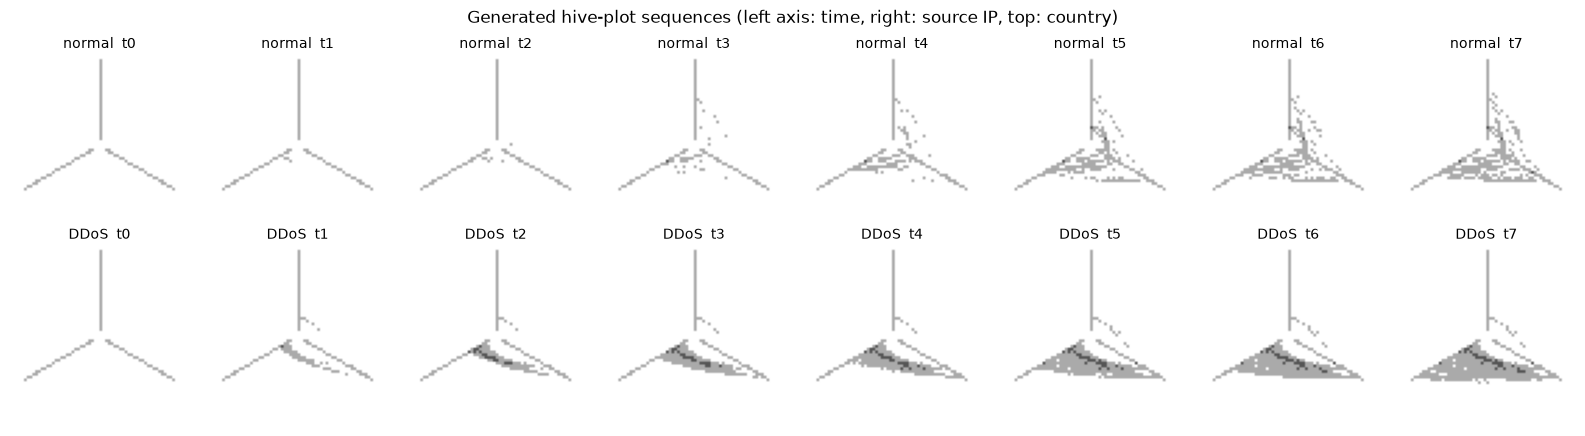

In [5]:
fig, ax = plt.subplots(2, N_STEPS, figsize=(2 * N_STEPS, 4.4))
for cls, name in enumerate(["normal", "DDoS"]):
    s = np.unique(seq_all[y_all == cls])[0]
    for t in range(N_STEPS):
        im = X_all[(seq_all == s) & (t_all == t)][0]
        ax[cls, t].imshow(im, cmap="gray_r", vmin=0, vmax=1); ax[cls, t].set_title(f"{name}  t{t}", fontsize=10); ax[cls, t].axis("off")
plt.suptitle("Generated hive-plot sequences (left axis: time, right: source IP, top: country)")
plt.tight_layout(); plt.show()

## 6. Split by sequence and flatten

Pictures of one honeypot session are strongly related (t5 contains everything in t4), so we split **sequences**, not pictures: 70 % of the sequences for training, 15 % for validation (early stopping) and 15 % for the final test. Every statistic and every classifier below is fitted on the training part only.

The autoencoders never see the labels. The labels and the time step only serve to colour pictures and to run the *probes* of Section 11.

In [6]:
seq_ids = np.unique(seq_all)
seq_cls = np.array([y_all[seq_all == s][0] for s in seq_ids])
from sklearn.model_selection import train_test_split
tr_seq, tmp_seq = train_test_split(seq_ids, test_size=VAL_FRAC + TEST_FRAC, stratify=seq_cls, random_state=SEED)
tmp_cls = np.array([y_all[seq_all == s][0] for s in tmp_seq])
va_seq, te_seq = train_test_split(tmp_seq, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC), stratify=tmp_cls, random_state=SEED)
idx = {"train": np.isin(seq_all, tr_seq), "val": np.isin(seq_all, va_seq), "test": np.isin(seq_all, te_seq)}
for k, m in idx.items():
    print(f"{k:5s}: {m.sum():5d} pictures, {len(np.unique(seq_all[m]))} sequences, DDoS share {y_all[m].mean():.2f}")

X_img = X_all[..., None]                    # (N, 64, 64, 1) for Keras
X_flat = X_all.reshape(len(X_all), -1)      # (N, 4096) for the classical classifiers

train:  1072 pictures, 134 sequences, DDoS share 0.50
val  :   232 pictures, 29 sequences, DDoS share 0.52
test :   232 pictures, 29 sequences, DDoS share 0.48


## 7. Classical supervised baselines on the pictures

The paper has no classical classifier (its models are unsupervised), but Rivas et al. (2019) trained an SVM and a CNN on the same kind of pictures and reached 95 % and 100 % accuracy. We train a random forest, an RBF support-vector machine and a logistic regression on the flattened 64x64 pictures (4,096 numbers) of the training sequences and test them on the test sequences. This tells us how hard the generated task is, which matters when we judge the latent spaces later. Blank t0 pictures are identical for both classes, so no classifier can do better than chance on them; we report accuracy with and without t0.

,accuracy,accuracy_no_t0,precision,recall,f1,fit_s,predict_s
model,,,,,,,
RandomForest,0.935,0.995,1.000,0.990,0.995,1.327,0.133
SVC(rbf),0.931,0.990,0.990,0.990,0.990,3.296,0.940
LogReg,0.832,0.877,0.974,0.765,0.857,0.937,0.010


,t0,t1,t2,t3,t4,t5,t6,t7
RandomForest accuracy per time step,0.517,0.966,1.0,1.0,1.0,1.0,1.0,1.0


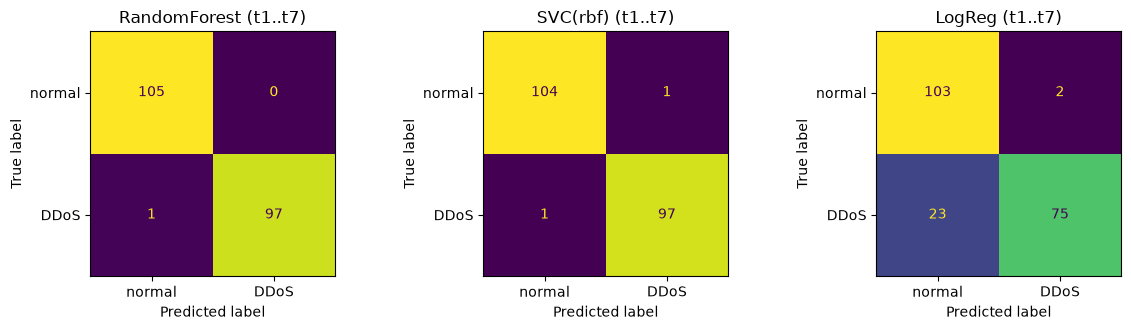

In [7]:
def run_classifiers(Xtr, ytr, Xte, yte, tte, names=("RandomForest", "SVC(rbf)", "LogReg")):
    rows = []
    for name in names:
        if name == "RandomForest":
            clf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
        elif name == "SVC(rbf)":
            clf = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED))
        else:
            clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED))
        t0 = time.perf_counter(); clf.fit(Xtr, ytr); fit_s = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = clf.predict(Xte); pred_s = time.perf_counter() - t0
        m = tte > 0
        rows.append(dict(model=name, accuracy=accuracy_score(yte, pred), accuracy_no_t0=accuracy_score(yte[m], pred[m]),
                         precision=precision_score(yte[m], pred[m]), recall=recall_score(yte[m], pred[m]),
                         f1=f1_score(yte[m], pred[m]), fit_s=fit_s, predict_s=pred_s))
        rows[-1]["_pred"] = pred; rows[-1]["_clf"] = clf
    return rows

base_rows = run_classifiers(X_flat[idx["train"]], y_all[idx["train"]], X_flat[idx["test"]], y_all[idx["test"]], t_all[idx["test"]])
baseline_pixels = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith("_")} for r in base_rows]).set_index("model")
display(baseline_pixels.round(3))

# accuracy per time step (Rivas 2019 Table II style) for the random forest
rf_pred = base_rows[0]["_pred"]; yte, tte = y_all[idx["test"]], t_all[idx["test"]]
per_t = pd.Series({f"t{t}": accuracy_score(yte[tte == t], rf_pred[tte == t]) for t in range(N_STEPS)}, name="RandomForest accuracy per time step")
display(per_t.to_frame().T.round(3))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a, r in zip(ax, base_rows):
    ConfusionMatrixDisplay(confusion_matrix(yte[tte > 0], r["_pred"][tte > 0]), display_labels=["normal", "DDoS"]).plot(ax=a, colorbar=False)
    a.set_title(f"{r['model']} (t1..t7)")
plt.tight_layout(); plt.show()

## 8. The quanvolutional layer

### The idea

A convolution slides a small window over the picture and applies the same small function to every window. In a *quanvolution* (Henderson et al. 2020, which the paper builds on) that function is a quantum circuit:

1. the 16 pixel values of a 4x4 window are written into 16 qubits, one pixel per qubit: `H` puts the qubit in superposition (paper Figure 4) and `RY(pi * pixel)` rotates it by an angle proportional to the ink;
2. a fixed circuit of random rotations and CNOT gates mixes the qubits (paper Section 3.3: angles drawn once from [0, 2pi) and never changed, so the layer is **not trainable**);
3. the expectation value of Pauli-Z of each qubit is measured; the 16 numbers become 16 output channels for that window position.

With stride 4 the 64x64 picture becomes a 16x16x16 feature map, which is what the trainable part of the autoencoder sees. Because the circuit is fixed and has no parameters to learn, the quanvolution can be computed once for the whole dataset before training, and fitting it on training data only is not an issue (nothing is fitted).

### Making the simulation affordable

A 16-qubit state has 65,536 amplitudes and one circuit takes about 30 ms on a CPU. A 64x64 picture has 256 windows, so the naive cost is around 8 s per picture. But hive plots are sparse line drawings with four grey levels, so most windows are repeated (blank, a piece of axis, a single line). We therefore simulate each **distinct** window once and look the result up for all its copies; this cuts the work by one to two orders of magnitude. The results are cached on disk.

Wire allocations: 16
Total gates: 99
Gate counts:
- Hadamard: 16
- RY: 35
- RX: 15
- CNOT: 19
- RZ: 14
Measurements:
- expval(PauliZ): 16
Depth: 14


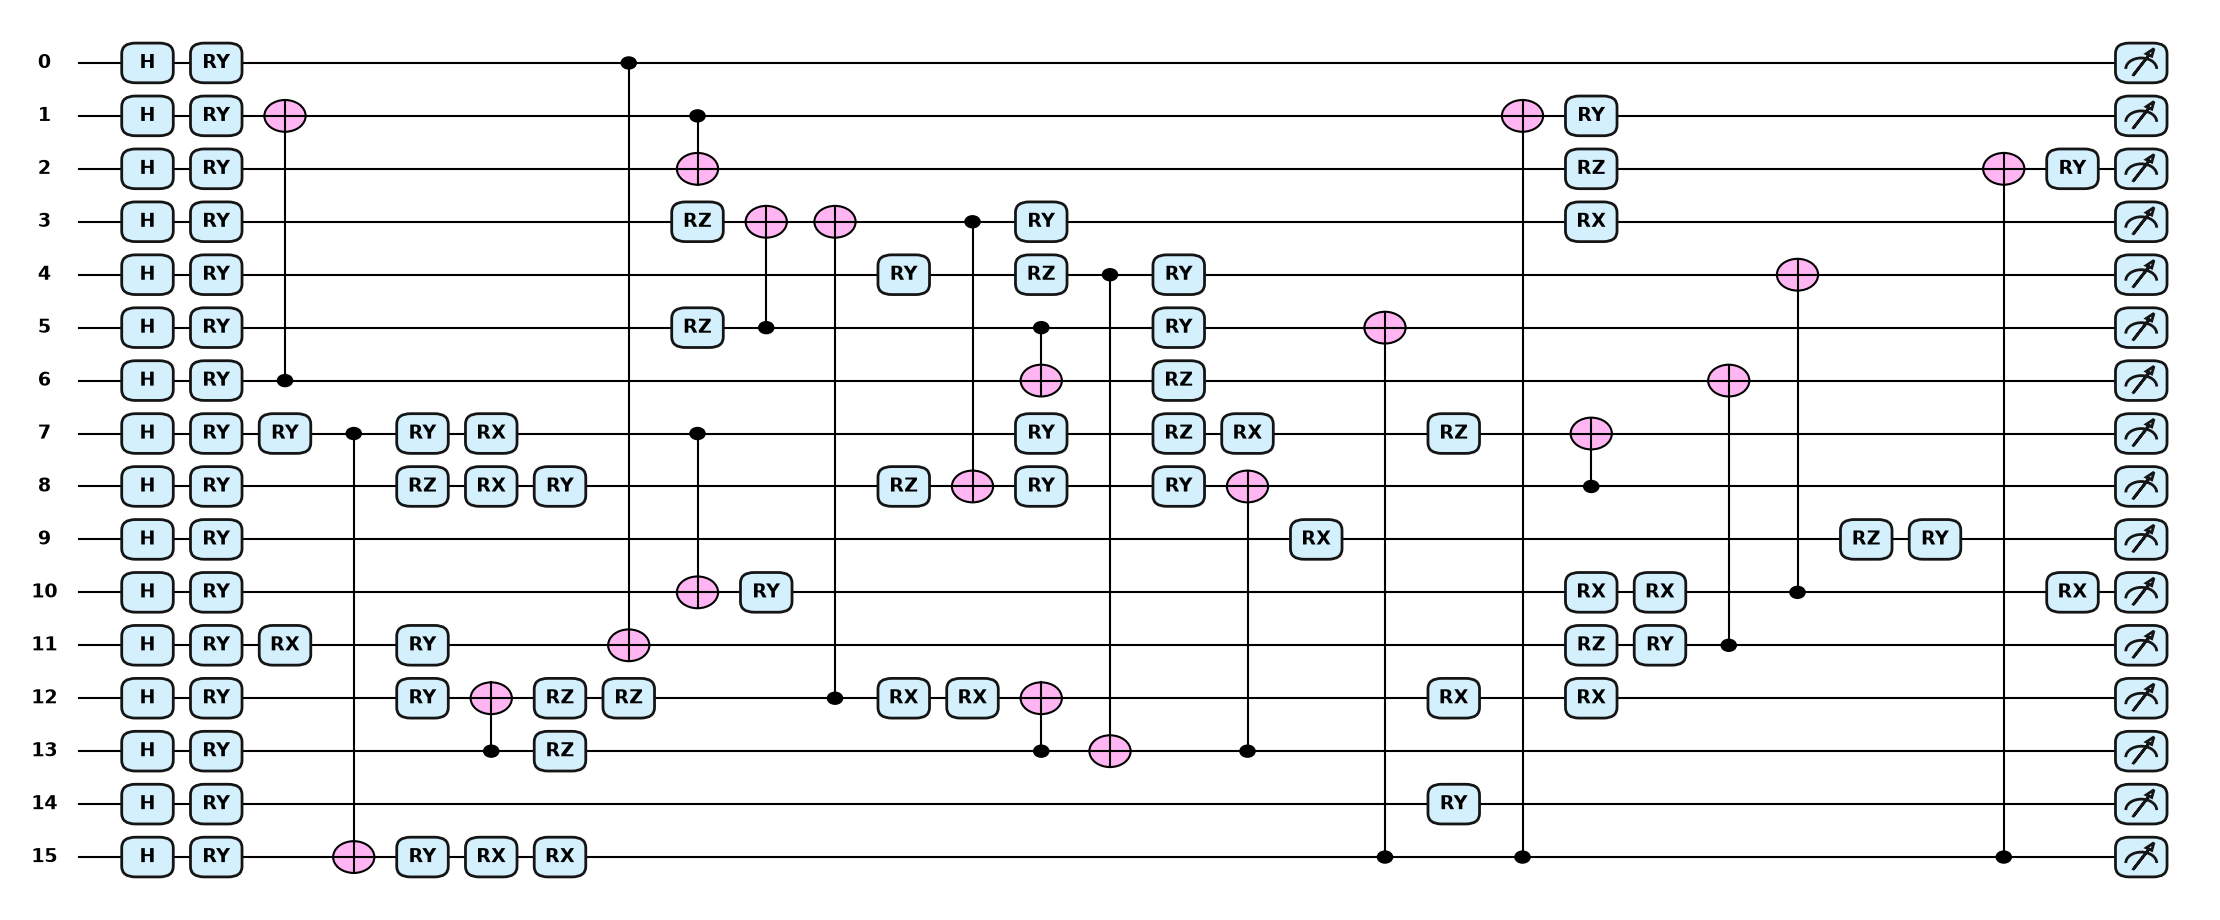

In [8]:
dev = qml.device("lightning.qubit", wires=N_QUBITS)
rng_circuit = np.random.default_rng(SEED)
QUANV_WEIGHTS = rng_circuit.uniform(0, 2 * np.pi, size=(QUANV_LAYERS, QUANV_ROTATIONS))   # fixed, never trained


@qml.qnode(dev, diff_method=None)
def quanv_circuit(patch):
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)                    # paper Figure 4: a Hadamard on every qubit
        qml.RY(np.pi * patch[i], wires=i)        # CHOICE: angle encoding of the pixel value
    qml.RandomLayers(QUANV_WEIGHTS, wires=range(N_QUBITS), ratio_imprim=QUANV_RATIO_CNOT, seed=SEED)
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]


sample_patch = X_all[9, 28:32, 28:32].ravel()
print(qml.specs(quanv_circuit, level="device")(sample_patch).resources)   # gate counts of the fixed circuit
fig, ax = qml.draw_mpl(quanv_circuit, level="device", style="pennylane")(sample_patch)
fig.set_size_inches(22, 9); plt.show()

In [9]:
def quanvolve(images):
    """Fixed quanvolution of (N, IMG, IMG) pictures -> (N, IMG//PATCH, IMG//PATCH, N_QUBITS) features in [0, 1]."""
    n, s = len(images), IMG // PATCH
    patches = images.reshape(n, s, PATCH, s, PATCH).transpose(0, 1, 3, 2, 4).reshape(-1, N_QUBITS)
    uniq, inv = np.unique(patches, axis=0, return_inverse=True)
    key = hashlib.md5(np.concatenate([uniq.ravel(), QUANV_WEIGHTS.ravel()]).tobytes()).hexdigest()[:12]
    cache = os.path.join(DATA_DIR, f"quanv_{key}.npy")
    global QUANV_CACHED
    QUANV_CACHED = os.path.exists(cache)
    if QUANV_CACHED:
        out_u = np.load(cache)
        print(f"loaded {len(uniq)} distinct windows from cache")
    else:
        out_u = np.empty((len(uniq), N_QUBITS), dtype=np.float32)
        t0 = time.perf_counter()
        for k, p in enumerate(uniq):
            out_u[k] = quanv_circuit(p)
            if (k + 1) % 1000 == 0 or k + 1 == len(uniq):
                el = time.perf_counter() - t0
                print(f"  {k + 1}/{len(uniq)} distinct windows, {el:.0f} s elapsed, ~{el / (k + 1) * (len(uniq) - k - 1):.0f} s left", flush=True)
        np.save(cache, out_u)
    feats = out_u[inv.ravel()].reshape(n, s, s, N_QUBITS)
    return (1.0 - feats) / 2.0, len(uniq)          # CHOICE: (1 - <Z>) / 2 maps the read-out to [0, 1]


print(f"{len(X_all)} pictures x {(IMG // PATCH) ** 2} windows = {len(X_all) * (IMG // PATCH) ** 2} windows in total")
t0 = time.perf_counter()
Q_all, n_distinct = quanvolve(X_all)
QUANV_SECONDS = time.perf_counter() - t0
print(f"quanvolution features {Q_all.shape}, {n_distinct} distinct windows simulated, {QUANV_SECONDS / 60:.1f} min")

1536 pictures x 256 windows = 393216 windows in total


  1000/9163 distinct windows, 83 s elapsed, ~680 s left


  2000/9163 distinct windows, 157 s elapsed, ~562 s left


  3000/9163 distinct windows, 227 s elapsed, ~465 s left


  4000/9163 distinct windows, 298 s elapsed, ~385 s left


...

  7000/9163 distinct windows, 506 s elapsed, ~156 s left


  8000/9163 distinct windows, 594 s elapsed, ~86 s left


  9000/9163 distinct windows, 659 s elapsed, ~12 s left


  9163/9163 distinct windows, 666 s elapsed, ~0 s left


quanvolution features (1536, 16, 16, 16), 9163 distinct windows simulated, 11.3 min


Paper Figure 8 in practice: one hive plot and its 16 quanvolution channels. Blank regions all map to the same constant, lines light up different channels differently.

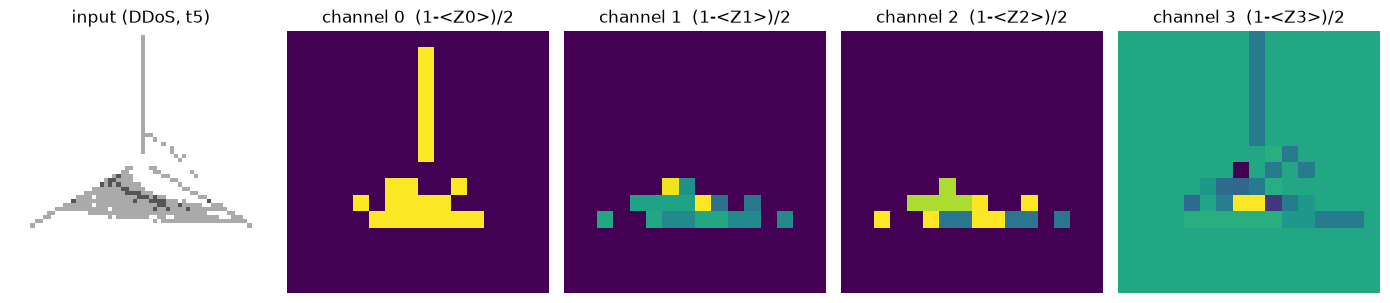

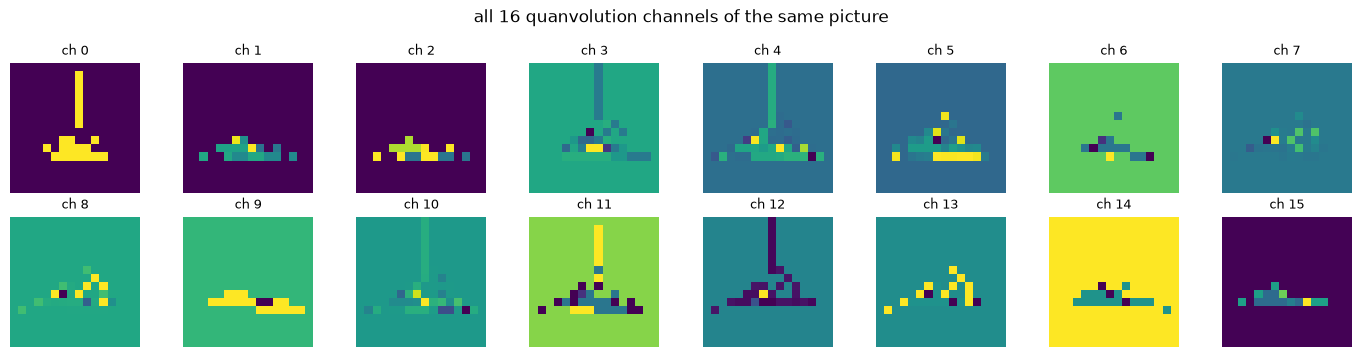

In [10]:
i = np.where((y_all == 1) & (t_all == 5))[0][0]
fig = plt.figure(figsize=(14, 3.6))
ax = fig.add_subplot(1, 5, 1); ax.imshow(X_all[i], cmap="gray_r", vmin=0, vmax=1); ax.set_title("input (DDoS, t5)"); ax.axis("off")
for c in range(4):
    ax = fig.add_subplot(1, 5, c + 2); ax.imshow(Q_all[i, :, :, c], cmap="viridis"); ax.set_title(f"channel {c}  (1-<Z{c}>)/2"); ax.axis("off")
plt.tight_layout(); plt.show()
fig, axs = plt.subplots(2, 8, figsize=(14, 3.6))
for c in range(16):
    axs[c // 8, c % 8].imshow(Q_all[i, :, :, c], cmap="viridis"); axs[c // 8, c % 8].set_title(f"ch {c}", fontsize=9); axs[c // 8, c % 8].axis("off")
plt.suptitle("all 16 quanvolution channels of the same picture"); plt.tight_layout(); plt.show()

## 9. The two autoencoders

Both networks follow paper Figure 7 scaled to 64x64 pictures. The **only** difference between them is the first layer:

* **CAE**: a trainable convolution with 16 filters of 4x4 and stride 4 (the same receptive field as the quanvolution) applied to the picture;
* **QAE**: the fixed quanvolution computed above (its 16x16x16 output is the network input).

After that both have: max-pooling 2x2, ReLU, 16 filters 3x3 stride 3, max-pooling 2x2, ReLU (which leaves a 1x1x16 map, exactly the geometry the paper's layer sizes give on 256x256 pictures), dense 512 and 128 with ReLU, the bottleneck of d units, and a mirrored decoder that ends in a sigmoid picture of 64x64. The loss is the binary cross-entropy of paper Eq. 2 between the picture and its reconstruction.

In [11]:
def encoder_tail(x, d):
    x = layers.MaxPooling2D(2)(x)                                  # paper: max-pool after the first convolution
    x = layers.ReLU()(x)
    x = layers.Conv2D(16, 3, strides=3, padding="valid")(x)        # 16 filters 3x3 stride 3, as in the paper
    x = layers.MaxPooling2D(2)(x)                                  # -> 1x1x16
    x = layers.ReLU()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dense(128, activation="relu")(x)
    return layers.Dense(d, name="bottleneck")(x)                   # CHOICE: linear bottleneck


def decoder(z):
    x = layers.Dense(128, activation="relu")(z)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dense(8 * 8 * 16, activation="relu")(x)
    x = layers.Reshape((8, 8, 16))(x)
    x = layers.Conv2DTranspose(16, 2, strides=2, activation="relu")(x)    # 8 -> 16
    x = layers.Conv2DTranspose(16, 4, strides=4, activation="relu")(x)    # 16 -> 64
    return layers.Conv2D(1, 3, padding="same", activation="sigmoid", name="reconstruction")(x)


def build_cae(d):
    inp = keras.Input((IMG, IMG, 1), name="picture")
    x = layers.Conv2D(16, PATCH, strides=PATCH, padding="valid", name="conv_4x4")(inp)   # CHOICE: 4x4/4 instead of 9x9/9 (64 px picture)
    z = encoder_tail(x, d)
    return keras.Model(inp, decoder(z), name=f"CAE_d{d}")


def build_qae(d):
    inp = keras.Input((IMG // PATCH, IMG // PATCH, N_QUBITS), name="quanvolution")        # fixed quantum layer output
    z = encoder_tail(inp, d)
    return keras.Model(inp, decoder(z), name=f"QAE_d{d}")


m = build_cae(2); m.summary(line_length=90)
print("trainable parameters: CAE", build_cae(2).count_params(), "| QAE", build_qae(2).count_params(),
      "(the QAE has no first-layer weights: its 4x4 filter is the fixed circuit)")

Model: "CAE_d2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                          ┃ Output Shape                 ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ picture (InputLayer)                  │ (None, 64, 64, 1)            │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv_4x4 (Conv2D)                     │ (None, 16, 16, 16)           │             272 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)          │ (None, 8, 8, 16)             │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ re_lu (ReLU)                          │ (None, 8, 8, 16)             │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                       │ (None, 2, 2, 16)             │           2,320 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)        │ (None, 1, 1, 16)             │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ re_lu_1 (ReLU)                        │ (None, 1, 1, 16)             │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ flatten (Flatten)                     │ (None, 16)                   │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense (Dense)                         │ (None, 512)                  │           8,704 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                       │ (None, 128)                  │          65,664 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ bottleneck (Dense)                    │ (None, 2)                    │             258 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                       │ (None, 128)                  │             384 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                       │ (None, 512)                  │          66,048 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                       │ (None, 1024)                 │         525,312 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ reshape (Reshape)                     │ (None, 8, 8, 16)             │               0 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2d_transpose (Conv2DTranspose)    │ (None, 16, 16, 16)           │           1,040 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ conv2d_transpose_1 (Conv2DTranspose)  │ (None, 64, 64, 16)           │           4,112 │
├───────────────────────────────────────┼──────────────────────────────┼─────────────────┤
│ reconstruction (Conv2D)               │ (None, 64, 64, 1)            │             145 │
└───────────────────────────────────────┴──────────────────────────────┴─────────────────┘

 Total params: 674,259 (2.57 MB)

 Trainable params: 674,259 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

trainable parameters: CAE 674259 | QAE 673987 (the QAE has no first-layer weights: its 4x4 filter is the fixed circuit)


## 10. Training

Adam with learning rate 0.001, binary cross-entropy, batches of 32, `ReduceLROnPlateau` after 5 flat epochs (paper Section 4.1), early stopping after 15 epochs without validation improvement with the best weights restored (paper Sections 3.2 / 3.3), and a cap of `MAX_EPOCHS`. The paper repeats training "with random initializations"; we do `N_SEEDS` restarts per model and bottleneck size and keep the first restart for the pictures.

The inputs are the pictures for the CAE and the pre-computed quanvolution maps for the QAE; the target is the picture in both cases.

In [12]:
inputs = {"CAE": X_img, "QAE": Q_all}
histories, models, train_times = {}, {}, {}


def train_one(kind, d, seed):
    keras.utils.set_random_seed(seed)
    model = build_cae(d) if kind == "CAE" else build_qae(d)
    model.compile(optimizer=keras.optimizers.Adam(LR), loss="binary_crossentropy")
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5)]
    Xin = inputs[kind]
    t0 = time.perf_counter()
    h = model.fit(Xin[idx["train"]], X_img[idx["train"]], validation_data=(Xin[idx["val"]], X_img[idx["val"]]),
                  epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=True, callbacks=cbs, verbose=0)
    return model, pd.DataFrame(h.history), time.perf_counter() - t0


for d in LATENT_DIMS:
    for kind in ("CAE", "QAE"):
        for r in range(N_SEEDS):
            model, hist, secs = train_one(kind, d, SEED + r)
            histories[(kind, d, r)] = hist; train_times[(kind, d, r)] = secs
            if r == 0:
                models[(kind, d)] = model
            print(f"{kind} d={d:2d} restart {r}: {len(hist):3d} epochs, best val loss {hist.val_loss.min():.4f} "
                  f"at epoch {int(hist.val_loss.idxmin()) + 1:3d}, {secs:.0f} s", flush=True)

CAE d= 2 restart 0:  80 epochs, best val loss 0.0426 at epoch  80, 161 s


CAE d= 2 restart 1:  80 epochs, best val loss 0.0425 at epoch  70, 194 s


CAE d= 2 restart 2:  80 epochs, best val loss 0.0421 at epoch  80, 199 s


QAE d= 2 restart 0:  80 epochs, best val loss 0.0430 at epoch  80, 146 s


QAE d= 2 restart 1:  80 epochs, best val loss 0.0431 at epoch  80, 147 s


...

CAE d=64 restart 1:  80 epochs, best val loss 0.0412 at epoch  80, 164 s


CAE d=64 restart 2:  80 epochs, best val loss 0.0435 at epoch  80, 146 s


QAE d=64 restart 0:  80 epochs, best val loss 0.0435 at epoch  80, 161 s


QAE d=64 restart 1:  80 epochs, best val loss 0.0426 at epoch  79, 158 s


QAE d=64 restart 2:  80 epochs, best val loss 0.0429 at epoch  80, 147 s


## 11. Reconstructions (paper Figures 9 and 10)

Eight test pictures, their CAE reconstruction and their QAE reconstruction from 2-D and from 64-D codes. The paper's claim is visual: a trained person can still tell an attack from normal traffic in the reconstruction. To give that claim a number we fit a random forest on the *reconstructed* training pictures and test it on the *reconstructed* test pictures: if the class can still be read off the reconstructions, the code kept the information that matters (the "trained human" of the paper is replaced by a trained forest).

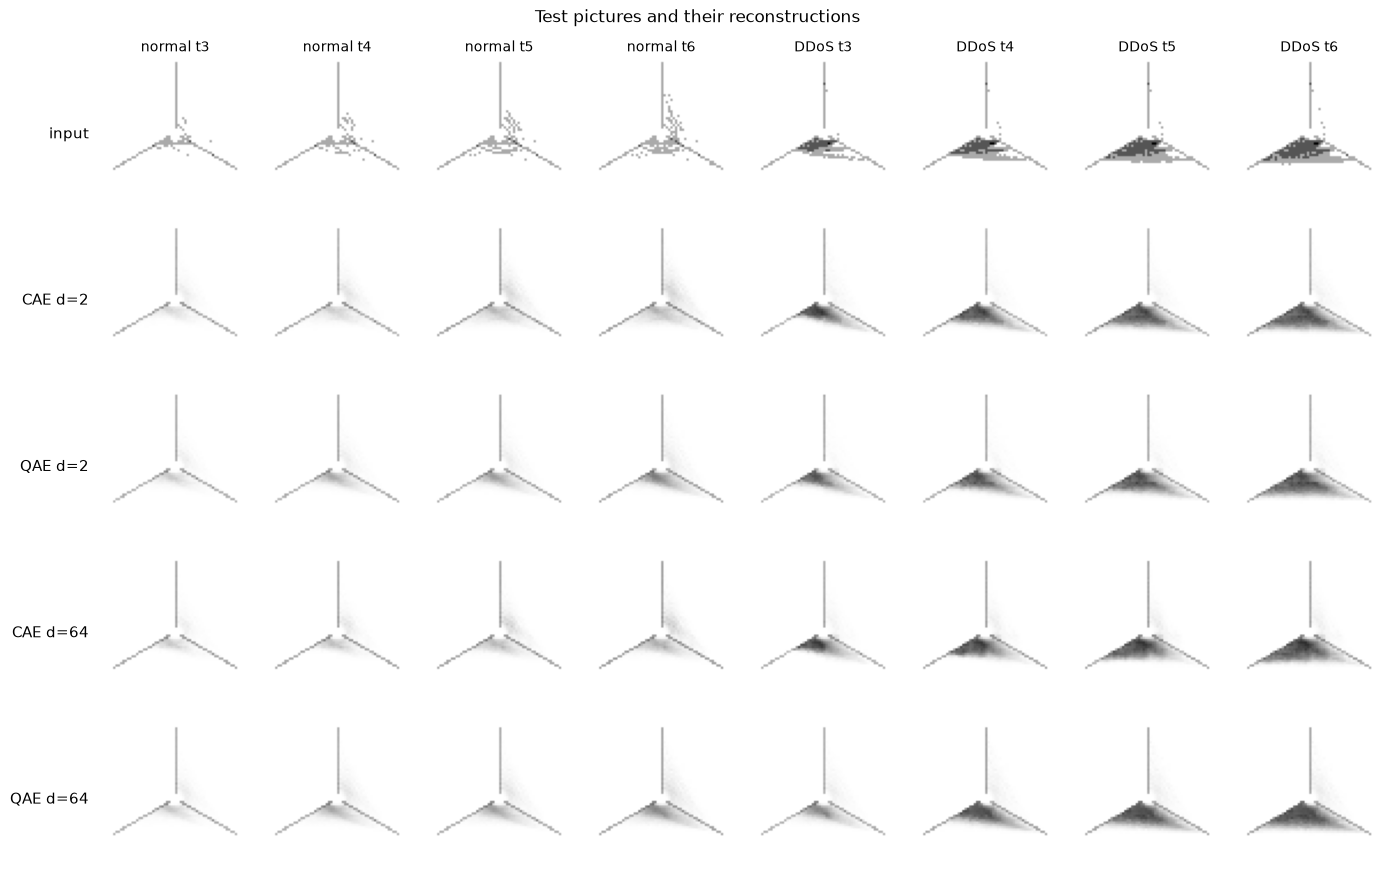

,model,d,test_bce,rf_accuracy_on_reconstructions
0,CAE,2,0.0403,1.0000
1,QAE,2,0.0408,0.9409
2,CAE,64,0.0393,0.9951
3,QAE,64,0.0411,0.9212


In [13]:
te, tr = np.where(idx["test"])[0], np.where(idx["train"])[0]
show = np.concatenate([te[(y_all[te] == 0) & (t_all[te] >= 3)][:4], te[(y_all[te] == 1) & (t_all[te] >= 3)][:4]])
recon, recon_train = {}, {}
for d in LATENT_DIMS:
    for kind in ("CAE", "QAE"):
        recon[(kind, d)] = models[(kind, d)].predict(inputs[kind][te], verbose=0)[..., 0]
        recon_train[(kind, d)] = models[(kind, d)].predict(inputs[kind][tr], verbose=0)[..., 0]

fig, ax = plt.subplots(5, 8, figsize=(14, 9))
rows = [("input", None)] + [(f"{kind} d={d}", (kind, d)) for d in LATENT_DIMS for kind in ("CAE", "QAE")]
for r, (name, key) in enumerate(rows):
    for c, i in enumerate(show):
        im = X_all[i] if key is None else recon[key][np.where(te == i)[0][0]]
        ax[r, c].imshow(im, cmap="gray_r", vmin=0, vmax=1); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(("normal" if y_all[i] == 0 else "DDoS") + f" t{t_all[i]}", fontsize=10)
    ax[r, 0].text(-6, 32, name, ha="right", va="center", fontsize=11)
plt.suptitle("Test pictures and their reconstructions"); plt.tight_layout(); plt.show()

recon_rows = []
for d in LATENT_DIMS:
    for kind in ("CAE", "QAE"):
        mask, mask_tr = t_all[te] > 0, t_all[tr] > 0
        rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(
            recon_train[(kind, d)].reshape(len(tr), -1)[mask_tr], y_all[tr][mask_tr])
        pred = rf.predict(recon[(kind, d)].reshape(len(te), -1))
        bce = float(keras.losses.binary_crossentropy(X_img[te], recon[(kind, d)][..., None]).numpy().mean())
        recon_rows.append(dict(model=kind, d=d, test_bce=bce,
                               rf_accuracy_on_reconstructions=accuracy_score(y_all[te][mask], pred[mask])))
recon_table = pd.DataFrame(recon_rows)
display(recon_table.round(4))

## 12. The learned latent spaces (paper Figures 11 and 12)

We cut each autoencoder at its bottleneck and encode the test pictures. Dots are normal traffic, crosses are DDoS, colours are the time step. For d = 64 the paper shows a UMAP projection; we use t-SNE, which is in scikit-learn.

Two numbers accompany the pictures (the paper gives none): the **silhouette score** of the two classes in the code space (1 = perfectly separated clusters, 0 = overlapping) and the test accuracy of a **logistic-regression probe** fitted on the training codes, which measures whether a straight line separates normal from attack in the latent space, as the paper suggests a "fine-tuned" classifier would. Blank t0 pictures are excluded from both numbers because they are identical for both classes; the t0 check of the paper (all t0 codes land on one point) is done separately.

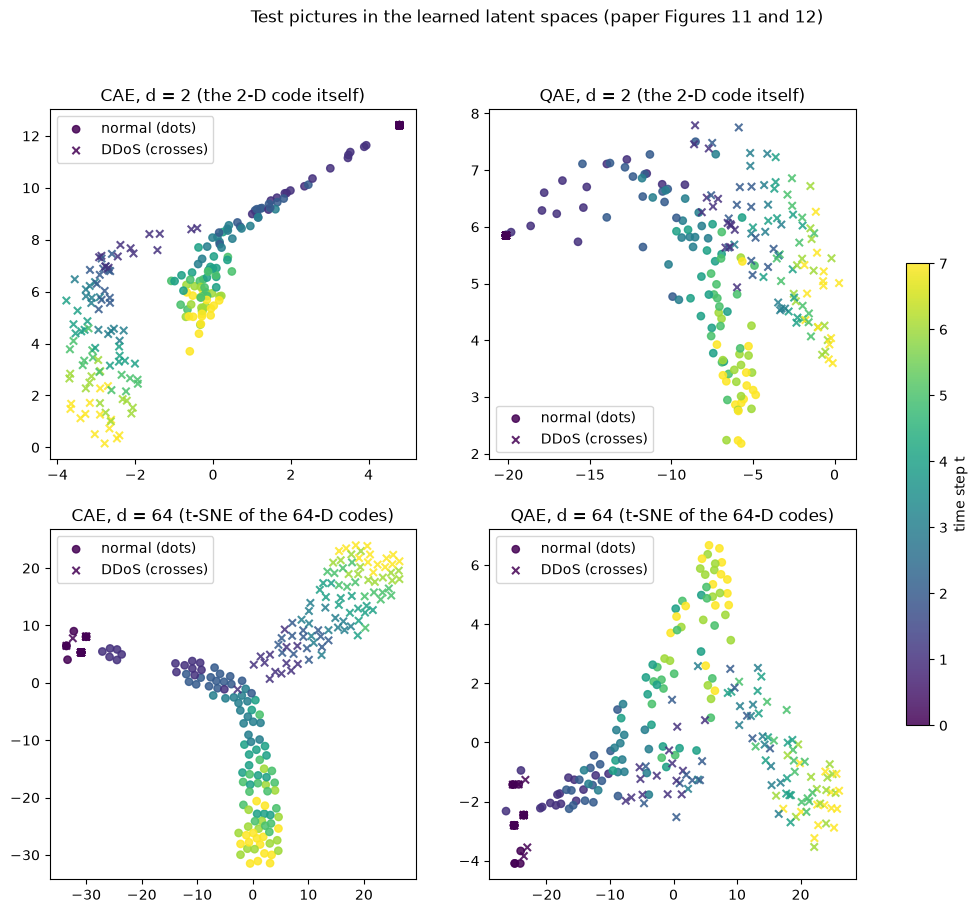

In [14]:
def encode(kind, d, mask):
    enc = keras.Model(models[(kind, d)].input, models[(kind, d)].get_layer("bottleneck").output)
    return enc.predict(inputs[kind][mask], verbose=0)

codes = {(kind, d, split): encode(kind, d, idx[split]) for d in LATENT_DIMS for kind in ("CAE", "QAE") for split in ("train", "test")}
yte, tte, ytr, ttr = y_all[idx["test"]], t_all[idx["test"]], y_all[idx["train"]], t_all[idx["train"]]

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
for row, d in enumerate(LATENT_DIMS):
    for col, kind in enumerate(("CAE", "QAE")):
        Z = codes[(kind, d, "test")]
        if d > 2:
            Z = TSNE(n_components=2, random_state=SEED, perplexity=30, init="pca").fit_transform(Z)
        a = ax[row, col]
        for cls, marker in ((0, "o"), (1, "x")):
            m = yte == cls
            sc = a.scatter(Z[m, 0], Z[m, 1], c=tte[m], cmap="viridis", marker=marker, s=28, vmin=0, vmax=N_STEPS - 1,
                           label="normal (dots)" if cls == 0 else "DDoS (crosses)", alpha=0.85)
        a.set_title(f"{kind}, d = {d}" + (" (t-SNE of the 64-D codes)" if d > 2 else " (the 2-D code itself)")); a.legend(loc="best")
plt.colorbar(sc, ax=ax, label="time step t", shrink=0.6); plt.suptitle("Test pictures in the learned latent spaces (paper Figures 11 and 12)"); plt.show()

In [15]:
latent_rows = []
for d in LATENT_DIMS:
    for kind in ("CAE", "QAE"):
        Ztr, Zte = codes[(kind, d, "train")], codes[(kind, d, "test")]
        mtr, mte = ttr > 0, tte > 0
        probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)).fit(Ztr[mtr], ytr[mtr])
        rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Ztr[mtr], ytr[mtr])
        svc = make_pipeline(StandardScaler(), SVC(kernel="rbf", random_state=SEED)).fit(Ztr[mtr], ytr[mtr])
        # t0 sanity check: spread of the t0 codes relative to the spread of all codes
        spread_all = np.sqrt(((Zte - Zte.mean(0)) ** 2).sum(1)).mean()
        z0 = Zte[tte == 0]; spread_t0 = np.sqrt(((z0 - z0.mean(0)) ** 2).sum(1)).mean()
        latent_rows.append(dict(model=kind, d=d, silhouette=silhouette_score(Zte[mte], yte[mte]),
                                probe_logreg_acc=accuracy_score(yte[mte], probe.predict(Zte[mte])),
                                probe_rf_acc=accuracy_score(yte[mte], rf.predict(Zte[mte])),
                                probe_svc_acc=accuracy_score(yte[mte], svc.predict(Zte[mte])),
                                probe_t_step_acc=accuracy_score(tte[mte], LogisticRegression(max_iter=3000, random_state=SEED).fit(
                                    StandardScaler().fit(Ztr[mtr]).transform(Ztr[mtr]), ttr[mtr]).predict(StandardScaler().fit(Ztr[mtr]).transform(Zte[mte]))),
                                t0_spread_ratio=spread_t0 / spread_all))
latent_table = pd.DataFrame(latent_rows)
display(latent_table.round(3))
print("probe_t_step_acc = accuracy of an 7-way logistic regression that reads the attack stage t1..t7 from the code (chance = 1/7 = 0.14)")
print("t0_spread_ratio  = how spread out the blank t0 codes are compared with all codes (0 = they collapse to one point)")

,model,d,silhouette,probe_logreg_acc,probe_rf_acc,probe_svc_acc,probe_t_step_acc,t0_spread_ratio
0,CAE,2,0.434,0.980,0.985,0.990,0.404,0.0
1,QAE,2,0.328,0.951,0.946,0.956,0.310,0.0
2,CAE,64,0.392,0.995,0.995,0.990,0.724,0.0
3,QAE,64,0.310,0.936,0.926,0.936,0.340,0.0


probe_t_step_acc = accuracy of an 7-way logistic regression that reads the attack stage t1..t7 from the code (chance = 1/7 = 0.14)
t0_spread_ratio  = how spread out the blank t0 codes are compared with all codes (0 = they collapse to one point)


## 13. Convergence and stability (paper Figures 13 to 16, Sections 4.3 and 4.4)

The paper's quantitative claims are about the **loss curves**:

* *Convergence*: "if the classical model requires N epochs to converge, our quanvolutional autoencoder accomplishes a similar convergence by epoch N - 15". We define the common target as the worse of the two best validation losses (plus 5 %), count for each model the first epoch at which its validation loss is at or below that target, and report the difference CAE - QAE in epochs. A positive number means the QAE got there first.
* *Stability*: the standard deviation of the validation loss over the epoch windows 1-15, 15-25 and 25-53 (the paper reports 0.06-0.10 for the QAE against about 1.0 for the CAE in the first window). Since the absolute size of a binary cross-entropy depends on the picture statistics, the comparable quantity is the **ratio** CAE / QAE.

Both are computed for every restart; the table shows mean and standard deviation over restarts.

In [16]:
def epochs_to_reach(series, target):
    hit = np.where(series.values <= target)[0]
    return int(hit[0]) + 1 if len(hit) else np.nan


conv_rows = []
for d in LATENT_DIMS:
    for r in range(N_SEEDS):
        hc, hq = histories[("CAE", d, r)], histories[("QAE", d, r)]
        worse_best = max(hc.val_loss.min(), hq.val_loss.min())
        target = 1.05 * worse_best                                           # a loss level both models reach
        ec, eq = epochs_to_reach(hc.val_loss, target), epochs_to_reach(hq.val_loss, target)
        ec2, eq2 = epochs_to_reach(hc.val_loss, 2 * worse_best), epochs_to_reach(hq.val_loss, 2 * worse_best)   # early phase: within a factor 2
        row = dict(d=d, restart=r, target_val_loss=target, epochs_CAE=ec, epochs_QAE=eq, QAE_earlier_by=ec - eq,
                   epochs_to_2x_CAE=ec2, epochs_to_2x_QAE=eq2, QAE_earlier_by_2x=ec2 - eq2,
                   best_val_CAE=hc.val_loss.min(), best_val_QAE=hq.val_loss.min(),
                   epochs_run_CAE=len(hc), epochs_run_QAE=len(hq),
                   s_per_epoch_CAE=train_times[("CAE", d, r)] / len(hc), s_per_epoch_QAE=train_times[("QAE", d, r)] / len(hq))
        for (a, b) in STABILITY_WINDOWS:
            sc = hc.val_loss.iloc[a - 1:b].std(); sq = hq.val_loss.iloc[a - 1:b].std()
            row[f"S{a}-{b}_CAE"] = sc; row[f"S{a}-{b}_QAE"] = sq; row[f"S{a}-{b}_ratio"] = sc / sq if sq > 0 else np.nan
        conv_rows.append(row)
conv = pd.DataFrame(conv_rows)
display(conv.round(4))
conv_summary = conv.drop(columns=["restart"]).groupby("d").agg(["mean", "std"])
print("mean and std over restarts:")
display(conv_summary[["QAE_earlier_by", "QAE_earlier_by_2x", "best_val_CAE", "best_val_QAE", "S1-15_CAE", "S1-15_QAE", "S1-15_ratio", "S15-25_ratio", "S25-53_ratio"]].round(4))
print("QAE_earlier_by    = epochs the CAE needs minus epochs the QAE needs to come within 5 % of the common best validation loss")
print("QAE_earlier_by_2x = the same for the early phase (within a factor 2 of that loss); positive = QAE first")

,d,restart,target_val_loss,epochs_CAE,epochs_QAE,QAE_earlier_by,epochs_to_2x_CAE,epochs_to_2x_QAE,QAE_earlier_by_2x,best_val_CAE,...,s_per_epoch_QAE,S1-15_CAE,S1-15_QAE,S1-15_ratio,S15-25_CAE,S15-25_QAE,S15-25_ratio,S25-53_CAE,S25-53_QAE,S25-53_ratio
0,2,0,0.0452,10,42,-32,1,1,0,0.0426,...,1.8275,0.0075,0.0038,1.9981,0.0002,0.0012,0.1623,0.0002,0.0004,0.5877
1,2,1,0.0453,12,25,-13,1,1,0,0.0425,...,1.8338,0.0067,0.0038,1.7598,0.0004,0.0015,0.2398,0.0003,0.0005,0.5368
2,2,2,0.0456,10,20,-10,1,1,0,0.0421,...,1.8469,0.0080,0.0041,1.9594,0.0003,0.0014,0.2185,0.0003,0.0003,1.0881
3,64,0,0.0456,10,14,-4,1,1,0,0.0410,...,2.0167,0.0070,0.0051,1.3844,0.0005,0.0002,2.2156,0.0005,0.0005,1.1213
4,64,1,0.0448,12,35,-23,1,1,0,0.0412,...,1.9720,0.0064,0.0055,1.1616,0.0003,0.0003,1.1278,0.0006,0.0009,0.6879
5,64,2,0.0457,26,16,10,1,1,0,0.0435,...,1.8412,0.0070,0.0049,1.4383,0.0002,0.0005,0.4534,0.0003,0.0003,1.0232


mean and std over restarts:


QAE_earlier_by          QAE_earlier_by_2x      best_val_CAE          \
             mean      std              mean  std         mean     std   
d                                                                        
2        -18.3333  11.9304               0.0  0.0       0.0424  0.0003   
64        -5.6667  16.5630               0.0  0.0       0.0419  0.0014   

   best_val_QAE         S1-15_CAE         S1-15_QAE         S1-15_ratio  \
           mean     std      mean     std      mean     std        mean   
d                                                                         
2        0.0432  0.0002    0.0074  0.0007    0.0039  0.0002      1.9058   
64       0.0430  0.0004    0.0068  0.0004    0.0051  0.0003      1.3281   

           S15-25_ratio         S25-53_ratio          
       std         mean     std         mean     std  
d                                                     
2   0.1279       0.2069  0.0401       0.7375  0.3047  
64  0.1467       1.2656  0.8891       0.9442  0.2273

QAE_earlier_by    = epochs the CAE needs minus epochs the QAE needs to come within 5 % of the common best validation loss
QAE_earlier_by_2x = the same for the early phase (within a factor 2 of that loss); positive = QAE first


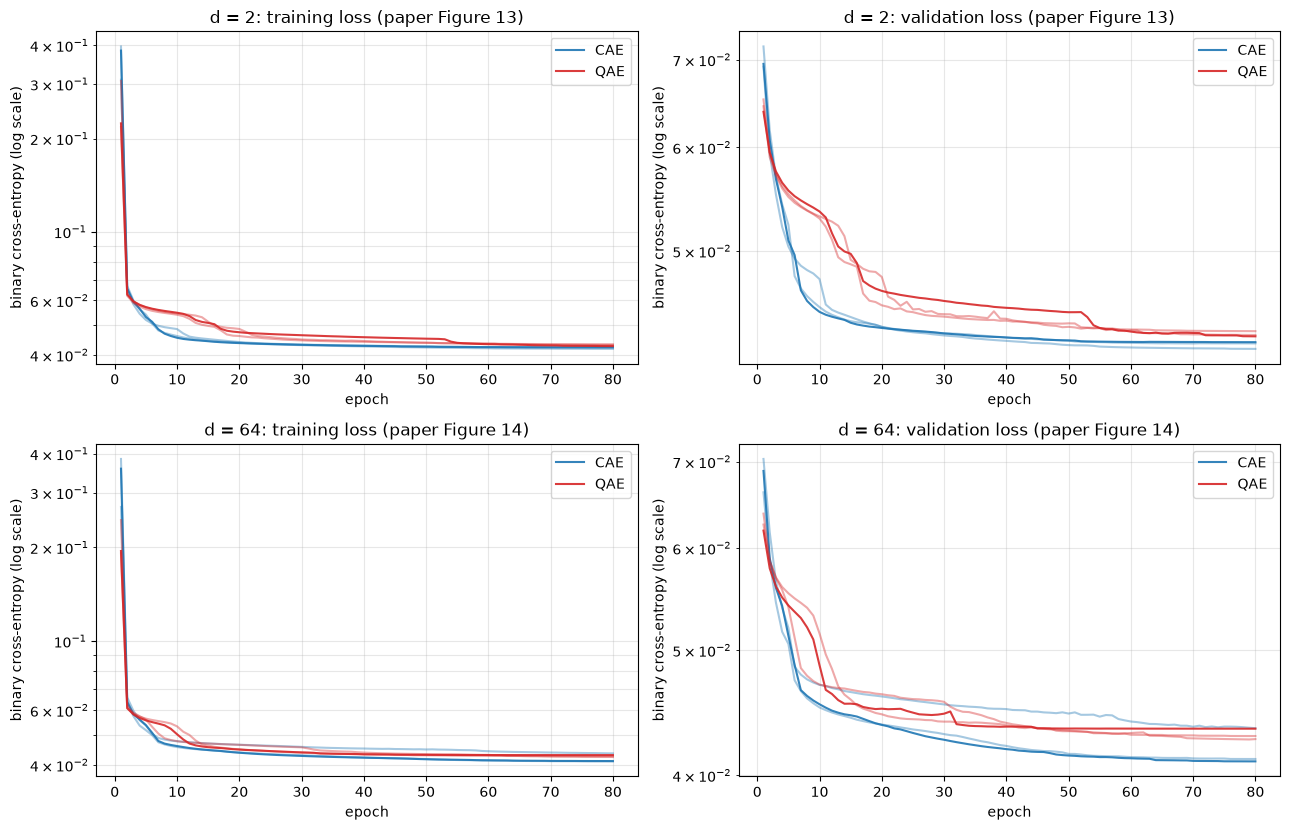

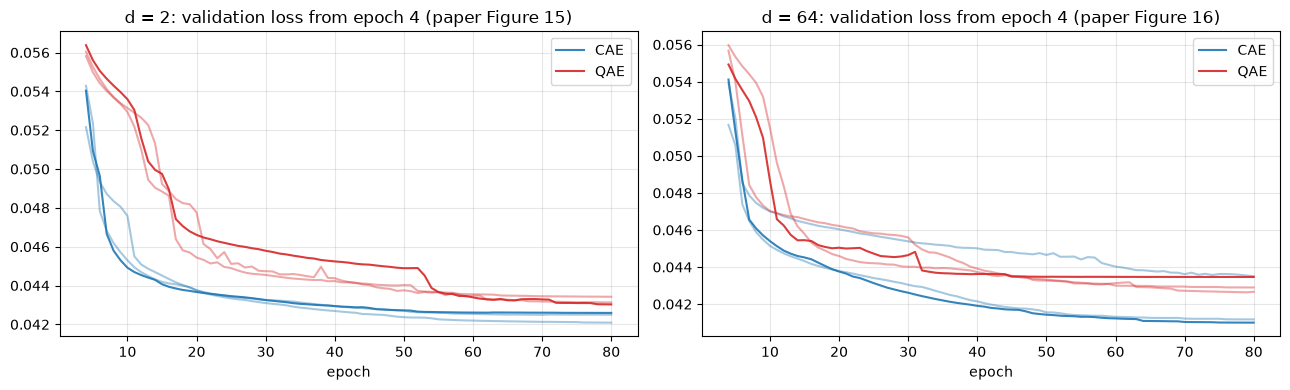

In [17]:
fig, ax = plt.subplots(len(LATENT_DIMS), 2, figsize=(13, 4.2 * len(LATENT_DIMS)))
for row, d in enumerate(LATENT_DIMS):
    for col, key in enumerate(("loss", "val_loss")):
        a = ax[row, col]
        for kind, color in (("CAE", "tab:blue"), ("QAE", "tab:red")):
            for r in range(N_SEEDS):
                h = histories[(kind, d, r)]
                a.plot(np.arange(1, len(h) + 1), h[key], color=color, alpha=0.9 if r == 0 else 0.4, label=f"{kind}" if r == 0 else None)
        a.set_title(f"d = {d}: {'training' if key == 'loss' else 'validation'} loss (paper Figure {13 if d == 2 else 14})")
        a.set_xlabel("epoch"); a.set_ylabel("binary cross-entropy (log scale)"); a.set_yscale("log"); a.legend(); a.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

# paper Figures 15 / 16: validation loss after the first epochs, where the stability is judged
fig, ax = plt.subplots(1, len(LATENT_DIMS), figsize=(13, 4))
for col, d in enumerate(LATENT_DIMS):
    a = ax[col]
    for kind, color in (("CAE", "tab:blue"), ("QAE", "tab:red")):
        for r in range(N_SEEDS):
            h = histories[(kind, d, r)]
            a.plot(np.arange(4, len(h) + 1), h.val_loss.iloc[3:], color=color, alpha=0.9 if r == 0 else 0.4, label=kind if r == 0 else None)
    a.set_title(f"d = {d}: validation loss from epoch 4 (paper Figure {15 if d == 2 else 16})"); a.set_xlabel("epoch"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 14. Side by side with the paper

The paper gives almost no numbers: the reconstruction and latent-space claims are pictures, and the convergence and stability claims are the two statements quoted above. The table lists each claim, what the paper says, what this notebook measured, and a verdict: "reproduced" when our measurement supports the statement, "not reached" when it contradicts it, "partially" when the direction agrees but not the size, and "cannot be checked" when the paper's statement has no measurable counterpart.

In [18]:
def verdict_recon(acc):
    return "reproduced" if acc >= 0.90 else ("partially" if acc >= 0.75 else "not reached")

rows = []
for d in LATENT_DIMS:
    for kind in ("CAE", "QAE"):
        acc = recon_table[(recon_table.model == kind) & (recon_table.d == d)].rf_accuracy_on_reconstructions.item()
        rows.append(dict(claim=f"Fig. {9 if kind == 'CAE' else 10}: {kind} reconstructions from d={d} keep the attack / normal information",
                         paper="visual: a trained human can still tell", notebook=f"RF fitted on reconstructed training pictures classifies reconstructed test pictures with {acc:.3f} accuracy",
                         verdict=verdict_recon(acc)))
for d in LATENT_DIMS:
    for kind in ("CAE", "QAE"):
        L = latent_table[(latent_table.model == kind) & (latent_table.d == d)].iloc[0]
        rows.append(dict(claim=f"Fig. {11 if d == 2 else 12}: {kind} d={d} latent space separates normal from DDoS without labels",
                         paper="visual: two groups" if d == 2 else "visual (UMAP): no-traffic / normal / DDoS groups",
                         notebook=f"silhouette {L.silhouette:.2f}, linear probe accuracy {L.probe_logreg_acc:.3f}, stage-t probe {L.probe_t_step_acc:.2f}",
                         verdict="reproduced" if (L.probe_logreg_acc >= 0.90 and L.silhouette > 0.1) else ("partially" if L.probe_logreg_acc >= 0.75 else "not reached")))
for d in LATENT_DIMS:
    for kind in ("CAE", "QAE"):
        L = latent_table[(latent_table.model == kind) & (latent_table.d == d)].iloc[0]
        rows.append(dict(claim=f"Fig. 11/12 sanity check: all t0 pictures map to one point ({kind}, d={d})", paper="visual: crosses and dots at t0 coincide",
                         notebook=f"t0 spread / overall spread = {L.t0_spread_ratio:.3f}", verdict="reproduced" if L.t0_spread_ratio < 0.05 else "not reached"))
for d in LATENT_DIMS:
    c = conv[conv.d == d]
    gain = c.QAE_earlier_by.mean(); gstd = c.QAE_earlier_by.std()
    deg = (c.best_val_QAE.mean() - c.best_val_CAE.mean()) / c.best_val_CAE.mean()
    rows.append(dict(claim=f"Sec. 4.2: QAE not degraded by the quantum layer (d={d})", paper="similar reconstruction / latent quality",
                     notebook=f"best val BCE: CAE {c.best_val_CAE.mean():.4f}, QAE {c.best_val_QAE.mean():.4f} ({deg:+.1%})",
                     verdict="reproduced" if abs(deg) <= 0.10 else ("partially" if abs(deg) <= 0.25 else "not reached")))
    rows.append(dict(claim=f"Sec. 4.3 / Fig. {13 if d == 2 else 14}: QAE reaches the same loss about 15 epochs earlier (d={d})", paper="N - 15 epochs, consistent over restarts",
                     notebook=f"QAE earlier by {gain:+.1f} +/- {0 if np.isnan(gstd) else gstd:.1f} epochs to within 5 % (restarts: {list(c.QAE_earlier_by.astype(int))}); early phase (within 2x): {c.QAE_earlier_by_2x.mean():+.1f} epochs",
                     verdict="reproduced" if gain >= 13 else ("partially" if gain > 0 else "not reached")))
    r1, r2, r3 = c["S1-15_ratio"].mean(), c["S15-25_ratio"].mean(), c["S25-53_ratio"].mean()
    rows.append(dict(claim=f"Sec. 4.4: QAE 10-15x more stable in epochs 1-15 (d={d})", paper="S(1-15): QAE 0.06-0.10 vs CAE about 1.0",
                     notebook=f"S(1-15): CAE {c['S1-15_CAE'].mean():.4f}, QAE {c['S1-15_QAE'].mean():.4f}, ratio CAE/QAE {r1:.2f}",
                     verdict="reproduced" if r1 >= 10 else ("partially" if r1 > 1.2 else "not reached")))
    rows.append(dict(claim=f"Sec. 4.4: QAE 5-10x more stable in epochs 15-25 and 2x in 25-53 (d={d})", paper="ratios 5-10 and 2",
                     notebook=f"ratio CAE/QAE: {r2:.2f} (15-25), {r3:.2f} (25-53)",
                     verdict="reproduced" if (r2 >= 5 and r3 >= 2) else ("partially" if (r2 > 1.2 or r3 > 1.2) else "not reached")))
rows.append(dict(claim="Hive-plot data: 16,000 pictures of 256x256 from the Marist honeypot", paper="Marist dataset (not published)",
                 notebook=f"{len(X_all)} regenerated pictures of {IMG}x{IMG}", verdict="cannot be checked (substitute data)"))
rows.append(dict(claim="Cost of the quantum layer", paper="not reported",
                 notebook=f"{n_distinct} distinct windows simulated in {QUANV_SECONDS / 60:.1f} min{' (loaded from cache)' if QUANV_CACHED else ''}; per epoch CAE {conv.s_per_epoch_CAE.mean():.1f} s vs QAE {conv.s_per_epoch_QAE.mean():.1f} s",
                 verdict="cannot be checked"))
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(comparison)
print("\nVerdict counts:"); print(comparison.verdict.value_counts().to_string())
print(f"\nTotal notebook time so far: {(time.perf_counter() - T_START) / 60:.1f} min")

,claim,paper,notebook,verdict
0,Fig. 9: CAE reconstructions from d=2 keep the attack / normal information,visual: a trained human can still tell,RF fitted on reconstructed training pictures classifies reconstructed test pictures with 1.000 accuracy,reproduced
1,Fig. 10: QAE reconstructions from d=2 keep the attack / normal information,visual: a trained human can still tell,RF fitted on reconstructed training pictures classifies reconstructed test pictures with 0.941 accuracy,reproduced
2,Fig. 9: CAE reconstructions from d=64 keep the attack / normal information,visual: a trained human can still tell,RF fitted on reconstructed training pictures classifies reconstructed test pictures with 0.995 accuracy,reproduced
3,Fig. 10: QAE reconstructions from d=64 keep the attack / normal information,visual: a trained human can still tell,RF fitted on reconstructed training pictures classifies reconstructed test pictures with 0.921 accuracy,reproduced
4,Fig. 11: CAE d=2 latent space separates normal from DDoS without labels,visual: two groups,"silhouette 0.43, linear probe accuracy 0.980, stage-t probe 0.40",reproduced
5,Fig. 11: QAE d=2 latent space separates normal from DDoS without labels,visual: two groups,"silhouette 0.33, linear probe accuracy 0.951, stage-t probe 0.31",reproduced
6,Fig. 12: CAE d=64 latent space separates normal from DDoS without labels,visual (UMAP): no-traffic / normal / DDoS groups,"silhouette 0.39, linear probe accuracy 0.995, stage-t probe 0.72",reproduced
7,Fig. 12: QAE d=64 latent space separates normal from DDoS without labels,visual (UMAP): no-traffic / normal / DDoS groups,"silhouette 0.31, linear probe accuracy 0.936, stage-t probe 0.34",reproduced
8,"Fig. 11/12 sanity check: all t0 pictures map to one point (CAE, d=2)",visual: crosses and dots at t0 coincide,t0 spread / overall spread = 0.000,reproduced
9,"Fig. 11/12 sanity check: all t0 pictures map to one point (QAE, d=2)",visual: crosses and dots at t0 coincide,t0 spread / overall spread = 0.000,reproduced



Verdict counts:
verdict
reproduced                             14
not reached                             3
partially                               3
cannot be checked (substitute data)     1
cannot be checked                       1

Total notebook time so far: 44.0 min


## 15. Reading the paper critically

**The data cannot be obtained.** The Data Availability Statement says that no dataset was generated or analysed, yet the whole study runs on 16,000 hive plots. The LCARS link in Section 3.1 points at the drawing tool, not at the pictures. We rebuilt the data from the recipe in the 2019 paper, so our pictures share the *logic* (few proxies, many hits; time / IP / country axes; eight cumulative steps with a blank t0) but not the pixels. Any statement about absolute loss values therefore cannot be compared; ratios and orderings can.

**What is actually quantum here.** The quanvolution has no trainable parameters and its angles are random. It is a fixed, non-linear random feature map of each 4x4 window, evaluated on a simulator with exact expectation values. Everything the model *learns* is classical and identical in both architectures. So the comparison in the paper is "trainable 4x4 (or 9x9) filters" versus "fixed random non-linear 4x4 features". A classical random feature map (random 4x4 filters followed by a non-linearity) would be the fair baseline for the question "is it the quantumness that helps?", and the paper does not include it. Exercise 3 asks you to add it.

**Faster convergence in epochs is not faster training.** The QAE skips the first convolution, so each epoch has fewer trainable parameters and the input is already a 16-channel map; converging in fewer epochs is plausible for that reason alone. But every picture first has to go through 256 circuits of 16 qubits. On our CPU the quanvolution of a few hundred pictures took longer than all the autoencoder training together (see the last row of the comparison table). On real hardware, the expectation values would also need thousands of shots per window.

**The stability numbers.** A standard deviation of about 1.0 for a binary cross-entropy that, in Figures 13-16, sits between 0.1 and 0.4, can only come from a few very large early values (the paper says Figures 15 and 16 "exclude initial outliers"). Our runs show what such a comparison depends on: with the same optimiser and the same picture statistics, both models' losses move on the same scale, and the ratio is nowhere near 10-15 unless one model has an unlucky start. Reporting the standard deviation over epochs also mixes *how fast the loss falls* with *how noisy it is*: a model that is still improving quickly in epochs 1-15 gets a larger standard deviation, which the paper reads as instability.

**Inconsistent hyper-parameters.** The learning rate is 0.001 in Sections 3.2 and 3.3 and 0.0001 with decay in Section 4.1; the early-stopping patience is 15 epochs (Sections 3.2, 3.3), 10 (Section 4.1) and 50 (Section 4.3). The text says "Qiskit implementation" in Algorithm 1 and TensorFlow Quantum in Section 3.3, while Section 2.5 says the circuit was built with PennyLane. None of this changes the idea, but it means the exact experiment cannot be re-run from the text.

**No numbers for the main claims.** The reconstruction and latent-space results are judged by eye. We added a probe accuracy, a silhouette score and the t0 check; they are our choice and another reasonable choice (for example k-means purity) may give different values. Equally, "converges 15 epochs earlier" depends on how "converged" is defined; we used a common loss target reached by both models.

**What the 2-D code actually encodes.** In our runs the 2-D codes of both models lie almost on a single curve ordered by the time step, i.e. by the amount of ink: attacks sit at the dark end, normal traffic at the light end, and the two overlap in the middle. That is also what paper Figure 11 shows once one looks past the colours (the t groups are ordered along one direction). A second latent dimension only becomes informative with more training data than a CPU budget allows here, which is why the 64-D code separates the classes much better than the 2-D one.

**The sanity check is weaker than it looks.** All t0 pictures are the same picture, so any deterministic encoder maps them to one point; it checks that the encoder is a function, not that it ignores spurious features.

**Unsupervised, but the task is easy.** Section 7 shows that simple supervised classifiers separate the pictures almost perfectly, as in Rivas et al. (2019). A latent space that separates the classes is then expected from any autoencoder that reconstructs the ink density; it does not show an advantage of the quantum layer, and the paper does not claim one on this point.

## 16. Exercises

1. **Trainable versus fixed.** Freeze the CAE's first convolution with random weights (set `trainable=False` on `conv_4x4` right after `build_cae`) and retrain. Does the frozen classical model also "converge earlier"? What does that say about the paper's Section 4.3?
2. **How random is good?** Change `QUANV_LAYERS` to 1 and to 4, and `QUANV_RATIO_CNOT` to 0 (no entanglement). Re-run from Section 8. Does entanglement change the latent-space probe accuracy or the convergence gain?
3. **A classical random feature map.** Replace the quanvolution by 16 random 4x4 filters followed by `tanh` (no training), computed once like `quanvolve`. Compare its loss curves and latent probes with the QAE. Is the quantum circuit doing more than a random non-linear projection?
4. **Fewer grey levels.** Set `GRAY_LEVELS = 2` (black and white). How many distinct windows remain, how much faster is the quanvolution, and does the probe accuracy drop?
5. **Harder data.** In `make_sequence`, give the attack more background traffic (`rng.integers(0, 3)` -> `rng.integers(3, 9)`) and fewer requests per proxy (`4, 16` -> `2, 6`). Re-run Sections 5 to 14. Which claims of the paper survive when normal and attack pictures look more alike?
6. **Real flows as hive plots.** Download a CICDDoS2019 file (see the `QSVM_DDoS_Said2023` notebook in this folder), group flows into 8 time windows, and draw hive plots with axes time / source IP / destination port. Does the autoencoder still separate the classes?